# Task 20 — Flight-delay propagation: which downstream flights will a late hub hit?

**Study unit:** ARI3217 — AI Enterprise Architectures and Transformation (University of Malta)
**Dataset:** [2015 Flight Delays and Cancellations](https://www.kaggle.com/datasets/usdot/flight-delays) (US DOT on-time data for every domestic flight of the 14 large carriers in 2015, with airline and airport reference files)
**Task family:** graph-aware tabular ML at a fixed forecast horizon, delay propagation along aircraft rotations, seasonal drift · **Companion task:** `02_card_fraud_tabular.ipynb` (forward evaluation, operating point, drift); `01_aml_graph_triage.ipynb` (graphs)

---

## The task card

> **Board question.** *When a hub falls an hour behind, which of the next departures will arrive 15 minutes late or worse? Can our operations-control centre name them two hours before departure, accurately enough to act on, and how much earlier is the warning still worth anything?*

**Business context.** An airline's operations-control centre (OCC) re-plans the day as it happens: it swaps aircraft, calls standby crews, holds connections, rebooks passengers. Each action needs lead time and costs money when unnecessary. The model joins a legacy estate of flight-operations system (schedule, aircraft movement messages), crew tracking, maintenance, passenger service and airport operations. It is Session 01's *online prediction* pattern with near-real-time features: each flight is scored two hours before departure (`POST /predict`) and a controller decides (*human-in-the-loop*). Delay travels: an aircraft that leaves Chicago late reaches Denver late and leaves Denver late. Hence the graph.

**What you will build from this notebook (see *Student tasks* at the end):**

1. the given **two-hour-ahead delay model** (minutes and a 15-minute flag), packaged and reproducible, evaluated forward by month, with the traps guarded by tests;
2. an **operating point** from the OCC's capacity and the cost of acting, in an ADR;
3. the **operational wrapper**: package, CI gate on a frozen later month, registry, model card, a seasonal monitoring plan;
4. the **airport–route–carrier graph**, an ablation of upstream-network context, and a grounded brief for controllers.

**Where this sits in the unit**

| Block | What this task exercises |
|---|---|
| 1 · EA for AI | Online scoring in an OCC; movement messages as a stream; crew and passenger systems downstream |
| 2 · MLOps | Point-in-time features, month splits, an F1 gate, seasonal drift |
| 3 · Semantic layer | Airports, routes, carriers and rotations as a graph; the upstream-context ablation |
| 4 · LLM/RAG | A network-state brief for controllers that cites flights (Session 10) |

**Assessment.** A *worked baseline plus tasks*; marks follow `docs/task-rubric.md`. The model is given: you are marked on how you package, evaluate, deploy, monitor and govern it, not on improving it. The notebook contains **deliberate traps**, each flagged with ⚠ in the text; turning each into a test is part of the task.

**Honesty note.** The data is **real**: the carriers' reports to the US Department of Transportation for 2015. It has no weather, crew or passenger data, and the delays already include whatever the real OCCs did. We measure how well delays can be *foreseen*, not what acting saves; the costs in Section 5 are assumptions.

---

## How this notebook is organised

The notebook has three parts. Parts A and B are given; Part C is your assignment. **The model is given:** you package, evaluate, deploy and monitor it; you do not design, tune or replace it.

| Part | Sections | What it contains | What you do with it |
|---|---|---|---|
| **A · Explore the data** | 1–3 | Dataset card, the airport-code and clock repair, first look at the network and the rotations | Read. Its quirks go into your model card and data contract; the repair and the rotation state become pipeline steps. |
| **B · The given model** | 4–6 | Features at two hours out and the network ablation, the operating point and the brief, the traps | Read, then package the code unchanged and reproduce its numbers (C2). |
| **C · Productionise it** | 7–10 | The model after the cut, the module spine, student tasks, hand-in checklist | Your work: package, test, gate, track, serve, monitor, govern. Section 7 shows the seasonal behaviour your monitoring must read correctly. |

**What you need from Parts A and B**

- **Code to package:** `get_raw` and `load_flights` (Section 1); the October code repair and the UTC clock (Section 2); `build_state` (Section 3); `features`, `flights_in`, `f1_threshold`, `scores` and `fit_eval` (Section 4); `operating` (Section 5); `psi` for monitoring (Section 7).
- **Parameters for `config/config.yaml`:** the CAPITALS in Section 0.
- **Numbers your pipeline must reproduce (C2):** 200,000 training flights (Jan–Jun sample), 150,000 July validation flights and all 503,956 operated August flights as the test; at two hours out, August F1 0.520, AUPRC 0.588 and MAE 15.96 minutes; threshold 0.72, giving 812 flags a day at 89.8 % precision and 24.2 % recall, worth $606,874 a day at the assumed costs.
- **Runtime:** about 3–4 minutes on a laptop (211 s on the build machine).

## 0 · Setup

*Before Part A · the parameters below move into `config/config.yaml`.*

In [1]:
%matplotlib inline
import os, time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pyarrow as pa
import pyarrow.csv as pc
import networkx as nx
import scipy.sparse as sp
from scipy.sparse.linalg import lsqr
import lightgbm as lgb
import sklearn
from sklearn.metrics import (f1_score, precision_score, recall_score, mean_absolute_error,
                             average_precision_score, precision_recall_curve)
from sklearn.model_selection import train_test_split
from IPython.display import display

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 140); pd.set_option("display.max_columns", 20)

# ---- parameters -------------------------------------------------------------
SEED = 3217
N_JOBS = 1                                 # one thread: faster on a shared laptop, and deterministic
KAGGLE_HANDLE = "usdot/flight-delays"
TRAIN_MONTHS = [1, 2, 3, 4, 5, 6]          # train: Jan – Jun 2015
VALID_MONTH, TEST_MONTH = 7, 8             # July chooses thresholds; August is the honest test
STREAM_MONTHS = [9, 10, 11, 12]            # the frozen model then runs on Sep – Dec as if in production
HORIZON_MIN = 120                          # score every flight two hours before its scheduled departure
HORIZONS = [30, 60, 120, 240, 480]         # "how early can we know?"
DELAY_MIN = 15                             # a flight is hit when it arrives 15+ minutes late (the DOT on-time definition)
LOOKBACK_MIN = 60                          # airport and network state: the hour before the prediction time
MIN_TURN_MIN = 30                          # minimum turnaround an aircraft needs on the ground (assumption)
N_TRAIN, N_VALID, N_STREAM = 200_000, 150_000, 100_000   # samples: Jan–Jun training, July thresholds, each stream month (shrink on a small
                                                         # laptop; the full-year event and rotation tables need ≈ 1 GB regardless)
OCC_CAPACITY_PER_HOUR = 150                # flags the OCC desk can work in an hour, network-wide (assumption — task C3)
ACTION_COST_USD = 150                      # cost of acting on a flag: swap, standby crew, rebooking (assumption — task C3)
AVOIDED_COST_USD = 1_000                   # disruption cost avoided when a flagged flight really is hit (assumption — task C3)

DATA_DIR = Path(os.environ.get("DATASETS_TASKS_DATA", Path.cwd().parent.parent / "data"))
RAW, PROCESSED = DATA_DIR / "raw" / "flight_delays", DATA_DIR / "processed"
RAW.mkdir(parents=True, exist_ok=True); PROCESSED.mkdir(parents=True, exist_ok=True)

SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]
INK, MUTED, GRID = "#0b0b0b", "#898781", "#e1e0d9"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c3c2b7",
    "axes.labelcolor": "#52514e", "xtick.color": MUTED, "ytick.color": MUTED, "text.color": INK,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.spines.top": False,
    "axes.spines.right": False, "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "legend.frameon": False, "figure.dpi": 110,
})
np.random.seed(SEED)
T_START = time.time()
print(f"pandas {pd.__version__} · lightgbm {lgb.__version__} · networkx {nx.__version__} · "
      f"scikit-learn {sklearn.__version__} · numpy {np.__version__}")

pandas 3.1.0 · lightgbm 4.7.0 · networkx 3.7 · scikit-learn 1.9.1 · numpy 2.5.4


# Part A — Explore the data

*Sections 1–3: read them; the quirks they find go into your model card and data contract.*

## 1 · Dataset card

*Part A · Explore · read; package `get_raw` and `load_flights`.*

| Field | Value |
|---|---|
| **Source** | Kaggle `usdot/flight-delays`, a packaging of the US DOT Bureau of Transportation Statistics (BTS) *Airline On-Time Performance* data |
| **Licence** | CC0: Public Domain |
| **Provenance** | Real. Each carrier reports its flights to the DOT monthly; delay causes are the carrier's own attribution |
| **Size** | 5,819,079 flights in 2015 (592 MB CSV), 14 carriers, 4,897 aircraft, 322 airports in `airports.csv` |
| **Files** | `flights.csv` (31 columns, one row per scheduled flight), `airlines.csv`, `airports.csv` (code, name, place, coordinates) |
| **Schema (flights)** | date, carrier, flight and tail number, origin, destination; scheduled and actual times; delays; taxi, wheels and air times; cancellation and diversion; five delay-cause columns |
| **Label** | `ARRIVAL_DELAY` in minutes, and *hit* = arrival delay ≥ 15 minutes; cancelled and diverted flights have none (Trap 3) |
| **Window used here** | All of 2015. Train on 200,000 flights sampled from Jan–Jun, set thresholds on July (150,000 sampled; all of July for capacity), test on all 503,956 operated August flights; Sep–Dec is the production stream, 100,000 a month |
| **PII** | None about people: no passenger or crew data. Tail numbers identify aircraft, whose registrations are public; we keep them, because rotations are the point |

**Known quirks you must handle (and should mention in your model card):**

1. ⚠ **October's airport codes are numbers**: five-digit DOT airport IDs instead of the IATA codes that the other months and `airports.csv` use (Section 2, Trap 2).
2. **Times are local `HHMM` integers with no time zone.** "Has the inbound aircraft left Denver yet?" against a deadline in Chicago needs one clock; Section 2 rebuilds it from the schedule.
3. ⚠ **Most columns are written after the flight**: actual times, taxi times and the five cause columns (Trap 1). The cause columns are filled exactly when the arrival delay is 15+ minutes and sum to it; `LATE_AIRCRAFT_DELAY` measures propagation, fine for analysis, useless as a feature.
4. ⚠ **Cancelled and diverted flights have no arrival delay** (Trap 3). The 14,721 flights without a tail number are all cancelled; 3,731 cancelled flights have a departure delay.
5. ⚠ **Tail numbers record the aircraft that actually flew**, after any swap the real OCC made, perhaps after τ. Rotation features built on them are optimistic; production must use the rotation as planned at τ (task C1).
6. **US Airways disappears in July**, folded into American (Section 7). Three airports lack coordinates (ECP, PBG, UST); Guam resolves to UTC−14, across the date line from UTC+10.

In [2]:
CAT = pa.dictionary(pa.int32(), pa.string())
COLUMNS = {"MONTH": pa.int8(), "DAY": pa.int8(), "DAY_OF_WEEK": pa.int8(), "AIRLINE": CAT, "FLIGHT_NUMBER": pa.int16(),
           "TAIL_NUMBER": CAT, "ORIGIN_AIRPORT": CAT, "DESTINATION_AIRPORT": CAT, "SCHEDULED_DEPARTURE": pa.int16(),
           "DEPARTURE_DELAY": pa.float32(), "TAXI_OUT": pa.float32(), "SCHEDULED_TIME": pa.float32(), "DISTANCE": pa.int16(),
           "SCHEDULED_ARRIVAL": pa.int16(), "ARRIVAL_DELAY": pa.float32(), "DIVERTED": pa.int8(), "CANCELLED": pa.int8(),
           "CANCELLATION_REASON": CAT, "AIR_SYSTEM_DELAY": pa.float32(), "SECURITY_DELAY": pa.float32(),
           "AIRLINE_DELAY": pa.float32(), "LATE_AIRCRAFT_DELAY": pa.float32(), "WEATHER_DELAY": pa.float32()}
RENAME = {"day_of_week": "dow", "tail_number": "tail_no", "origin_airport": "origin", "destination_airport": "dest",
          "scheduled_departure": "sched_dep", "scheduled_arrival": "sched_arr", "scheduled_time": "sched_time",
          "departure_delay": "dep_delay", "arrival_delay": "arr_delay",
          "cancellation_reason": "cancel_reason"}
CAUSES = ["late_aircraft_delay", "airline_delay", "air_system_delay", "weather_delay", "security_delay"]

def get_raw(filename: str) -> Path:
    local = RAW / filename
    if local.exists():
        return local
    import kagglehub
    return Path(kagglehub.dataset_download(KAGGLE_HANDLE, path=filename))

def load_flights() -> pd.DataFrame:
    """flights.csv with only the columns we use, compact dtypes, cached as Parquet (≈ 100 MB on disk, ≈ 330 MB in memory)."""
    cache = PROCESSED / "20_flights.parquet"
    if not cache.exists():
        t = time.time()
        tbl = pc.read_csv(get_raw("flights.csv"),
                          convert_options=pc.ConvertOptions(include_columns=list(COLUMNS), column_types=COLUMNS))
        df = tbl.to_pandas(); del tbl
        df.columns = [c.lower() for c in df.columns]
        df.to_parquet(cache); del df
        print(f"loaded + cached in {time.time()-t:.0f}s")
    df = pd.read_parquet(cache).rename(columns=RENAME)
    pa.default_memory_pool().release_unused()            # hand Arrow's spare read buffers back to the OS
    for c in ["tail_no", "cancel_reason"]:                # empty strings are missing values
        if "" in df[c].cat.categories:
            df[c] = df[c].cat.remove_categories([""])
    return df

fl = load_flights()
# ---- governance on load: no personal data in this file. Tail numbers are aircraft registrations (public);
# we keep them. Post-flight columns we never use (actual times, wheels, taxi-in, air time) are simply not loaded.
n_num = sum(c.isdigit() for c in fl.origin.cat.categories)
print(f"{len(fl):,} flights · {fl.airline.nunique()} carriers · {fl.tail_no.nunique():,} aircraft · "
      f"origin codes: {fl.origin.nunique() - n_num} IATA + {n_num} numeric · cancelled {fl.cancelled.mean():.2%} · diverted {fl.diverted.mean():.2%} · "
      f"no tail number {fl.tail_no.isna().sum():,} ({fl.loc[fl.tail_no.isna(), 'cancelled'].mean():.0%} of them cancelled) · "
      f"cancelled yet with a departure delay {int((fl.cancelled.eq(1) & fl.dep_delay.notna()).sum()):,} · "
      f"{fl.memory_usage(deep=True).sum()/1e6:.0f} MB")
fl.head(3)

5,819,079 flights · 14 carriers · 4,897 aircraft · origin codes: 322 IATA + 306 numeric · cancelled 1.54% · diverted 0.26% · no tail number 14,721 (100% of them cancelled) · cancelled yet with a departure delay 3,731 · 332 MB


,month,day,dow,airline,flight_number,tail_no,origin,dest,sched_dep,dep_delay,...,sched_arr,arr_delay,diverted,cancelled,cancel_reason,air_system_delay,security_delay,airline_delay,late_aircraft_delay,weather_delay
0,1,1,4,AS,98,N407AS,ANC,SEA,5,-11.0,...,430,-22.0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
1,1,1,4,AA,2336,N3KUAA,LAX,PBI,10,-8.0,...,750,-9.0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
2,1,1,4,US,840,N171US,SFO,CLT,20,-2.0,...,806,5.0,0,0,NaN,NaN,NaN,NaN,NaN,NaN


## 2 · Integrity first: airport codes and clocks

*Part A · Explore · read; package the October code repair and the UTC clock as pipeline steps, and C1 turns the join check into a test.*

A graph built from rows whose airports do not join has holes in it. So, first: does every origin and destination join to `airports.csv`, in every month?

In [3]:
airports = pd.read_csv(get_raw("airports.csv"))
airlines = pd.read_csv(get_raw("airlines.csv")).set_index("IATA_CODE").AIRLINE
known = set(airports.IATA_CODE)
numeric_codes = [c for c in fl.origin.cat.categories.union(fl.dest.cat.categories) if c.isdigit()]
join = pd.DataFrame({"month": fl.month, "origin_unjoined": ~fl.origin.isin(known), "dest_unjoined": ~fl.dest.isin(known),
                     "numeric_origin": fl.origin.isin(numeric_codes)}).groupby("month").agg(
    flights=("origin_unjoined", "size"), origin_unjoined=("origin_unjoined", "sum"),
    dest_unjoined=("dest_unjoined", "sum"), numeric_origin=("numeric_origin", "sum"))
display(join.T.style.format("{:,}"))
print(f"airports.csv: {len(airports)} airports, {airports.LATITUDE.isna().sum()} without coordinates · "
      f"{len(numeric_codes)} numeric airport codes, all in October · an inner join with airports.csv silently drops "
      f"{join.origin_unjoined.sum():,} flights ({join.origin_unjoined.sum()/len(fl):.1%} of the year)")

month,1,2,3,4,5,6,7,8,9,10,11,12
flights,"469,968","429,191","504,312","485,151","496,993","503,897","520,718","510,536","464,946","486,165","467,972","479,230"
origin_unjoined,0,0,0,0,0,0,0,0,0,"486,165",0,0
dest_unjoined,0,0,0,0,0,0,0,0,0,"486,165",0,0
numeric_origin,0,0,0,0,0,0,0,0,0,"486,165",0,0


airports.csv: 322 airports, 3 without coordinates · 307 numeric airport codes, all in October · an inner join with airports.csv silently drops 486,165 flights (8.4% of the year)


The reports are true: **all 486,165 October flights** carry five-digit DOT airport IDs, and no other month has a single unjoined code. The dataset ships no lookup table, but schedules repeat. The same carrier, flight number, departure time and distance in September or November names the airports, so each October flight votes and each numeric code takes the IATA code with most votes.

In [4]:
octo = fl.month.values == 10
KEY = ["airline", "flight_number", "sched_dep", "distance"]
named = fl.loc[np.isin(fl.month.values, [9, 11]), KEY + ["origin", "dest"]]
votes = []
for side in ["origin", "dest"]:
    ref = (named.groupby(KEY + [side], observed=True).size().reset_index(name="n_ref")
                .sort_values("n_ref").drop_duplicates(KEY, keep="last"))
    num = fl.loc[octo, KEY + [side]].groupby(KEY + [side], observed=True).size().reset_index(name="n")
    m = num.merge(ref, on=KEY, suffixes=("_num", "_iata"))
    votes.append(m[[f"{side}_num", f"{side}_iata", "n"]].set_axis(["num", "iata", "n"], axis=1))
votes = pd.concat(votes).astype({"num": str, "iata": str}).groupby(["num", "iata"]).n.sum().reset_index()
votes["agreement"] = votes.n / votes.groupby("num").n.transform("sum")
code_map = votes.sort_values("n").drop_duplicates("num", keep="last").set_index("num")
CODE = code_map.iata.to_dict()
del named, votes, ref, num, m

before = len(fl)
for side in ["origin", "dest"]:                                   # relabel the categories, not 5.8 M strings
    lut = np.array([CODE.get(c, None if c.isdigit() else c) for c in fl[side].cat.categories], dtype=object)
    fl[side] = pd.Categorical(lut[fl[side].cat.codes.values])
fl = fl[fl.origin.notna().values & fl.dest.notna().values].reset_index(drop=True)
AIRPORTS = sorted(set(fl.origin.cat.categories) | set(fl.dest.cat.categories))
fl["origin"] = fl.origin.cat.set_categories(AIRPORTS); fl["dest"] = fl.dest.cat.set_categories(AIRPORTS)
pa.default_memory_pool().release_unused()
top = code_map.sort_values("n", ascending=False).head(6)
print(f"recovered {len(CODE)} of {len(numeric_codes)} numeric codes · lowest agreement {code_map.agreement.min():.1%} · "
      f"IATA codes claimed twice: {int(code_map.iata.duplicated().sum())} · dropped {before - len(fl):,} October flights "
      f"touching the {len(numeric_codes) - len(CODE)} unrecovered codes")
print("largest:", ", ".join(f"{k}→{v}" for k, v in top.iata.items()), "· every airport now joins:",
      bool(fl.origin.isin(known).all() and fl.dest.isin(known).all()))

recovered 300 of 307 numeric codes · lowest agreement 99.0% · IATA codes claimed twice: 0 · dropped 1,097 October flights touching the 7 unrecovered codes
largest: 13930→ORD, 11298→DFW, 11292→DEN, 10397→ATL, 12892→LAX, 14771→SFO · every airport now joins: True


300 of the 307 numeric codes come back with at least 99 % agreement, and no IATA code is claimed twice. The seven unrecovered codes touch 1,097 flights; we drop them and say so in the model card.

**The clock.** Scheduled arrival minus departure minus block time is the time-zone difference between two airports. One equation per route, solved by sparse least squares and anchored at Atlanta, gives every airport's UTC offset, for standard and daylight time. From here on, times are minutes since 1 January 2015, UTC.

In [5]:
CUMDAYS = np.cumsum([0, 31, 28, 31, 30, 31, 30, 31, 31, 30, 31, 30])
fl["doy"] = (CUMDAYS[fl.month.values - 1] + fl.day.values).astype(np.int16)
DST = (fl.doy.values >= 67) & (fl.doy.values < 305)                     # US daylight time in 2015: 8 Mar – 31 Oct
hhmm = lambda x: (x.astype(np.int32) // 100) * 60 + x.astype(np.int32) % 100
shift = (hhmm(fl.sched_arr.values) - hhmm(fl.sched_dep.values) - fl.sched_time.values) % 1440
shift = np.round(np.where(shift > 720, shift - 1440, shift) / 60) * 60    # destination offset − origin offset (minutes)
UTC_OFFSET, bad_pairs, n_eq = {}, 0, 0
for dst in (False, True):
    m = DST == dst
    e = (pd.DataFrame({"o": fl.origin.values[m], "d": fl.dest.values[m], "s": shift[m]})
           .groupby(["o", "d"], observed=True).s.agg(lambda s: s.mode().iat[0]).reset_index())
    ix = {a: i for i, a in enumerate(AIRPORTS)}; n = len(e); n_eq += n
    A = sp.csr_matrix((np.r_[np.ones(n), -np.ones(n), [1.0]],
                       (np.r_[np.arange(n), np.arange(n), [n]], np.r_[e.d.map(ix), e.o.map(ix), [ix["ATL"]]])),
                      shape=(n + 1, len(AIRPORTS)))
    x = lsqr(A, np.r_[e.s.values, [-240.0 if dst else -300.0]], atol=1e-10, btol=1e-10)[0]
    UTC_OFFSET[dst] = pd.Series(np.round(x / 60) * 60, index=AIRPORTS)
    bad_pairs += int((np.abs(A[:n] @ UTC_OFFSET[dst].values - e.s.values) > 1).sum())
off_o = np.where(DST, fl.origin.map(UTC_OFFSET[True]).astype(float), fl.origin.map(UTC_OFFSET[False]).astype(float))
off_d = np.where(DST, fl.dest.map(UTC_OFFSET[True]).astype(float), fl.dest.map(UTC_OFFSET[False]).astype(float))
fl["sdep_utc"] = ((fl.doy.values.astype(np.int32) - 1) * 1440 + hhmm(fl.sched_dep.values) - off_o).astype(np.float32)
fl["sarr_utc"] = (fl.sdep_utc + fl.sched_time).astype(np.float32)
fl["adep_utc"] = (fl.sdep_utc + fl.dep_delay).astype(np.float32)        # actual departure (NaN if it never left)
fl["aarr_utc"] = (fl.sarr_utc + fl.arr_delay).astype(np.float32)        # actual arrival (NaN if cancelled or diverted)
fl["hour"] = (fl.sched_dep.values // 100).astype(np.int8)
consistent = np.mean(np.abs((fl.sarr_utc.values + off_d) % 1440 - hhmm(fl.sched_arr.values) % 1440) < 1)
del shift, off_o, off_d, e, A, x
offs = pd.DataFrame({"winter": UTC_OFFSET[False], "summer": UTC_OFFSET[True]}).loc[["ATL", "ORD", "DEN", "PHX", "LAX", "ANC", "HNL"]] / 60
print(f"{bad_pairs} of {n_eq:,} route equations (standard + daylight time) disagree with the fitted offsets · scheduled arrivals reproduced for "
      f"{consistent:.3%} of flights")
print("UTC offset (hours):", offs.astype(int).T.to_dict())

5 of 8,998 route equations (standard + daylight time) disagree with the fitted offsets · scheduled arrivals reproduced for 99.992% of flights
UTC offset (hours): {'ATL': {'winter': -5, 'summer': -4}, 'ORD': {'winter': -6, 'summer': -5}, 'DEN': {'winter': -7, 'summer': -6}, 'PHX': {'winter': -7, 'summer': -7}, 'LAX': {'winter': -8, 'summer': -7}, 'ANC': {'winter': -9, 'summer': -8}, 'HNL': {'winter': -10, 'summer': -10}}


The offsets are the real ones, quirks included: Phoenix stays at UTC−7 all year, as Arizona keeps no daylight time. 99.99 % of scheduled arrivals are reproduced to the minute. A pipeline that looked up time zones by IATA code would have lost October here too (Trap 2).

## 3 · First look: late flights, late aircraft and the network

*Part A · Explore · read; package `build_state`, the rotation backbone of Section 4's features.*

What a controller asks first: how often flights are late, when, and *why*. The cause columns answer *why*, after the fact.

hit rate by month: 1:21.0% 2:23.3% 3:19.4% 4:17.2% 5:18.3% 6:23.5% 7:20.9% 8:18.7% 9:13.0% 10:12.4% 11:15.3% 12:20.6%
cancelled by month: 1:2.5% 2:4.8% 3:2.2% 4:0.9% 5:1.1% 6:1.8% 7:0.9% 8:1.0% 9:0.4% 10:0.5% 11:1.0% 12:1.7%


hit rate (operated flights): 18.6% · mean arrival delay 4.4 min, median -5 · delay minutes by cause: late_aircraft 39.8%, airline 32.2%, air_system 22.9%, weather 4.9%, security 0.1%
late-aircraft share of delay minutes by month: 36.0%–43.6% · largest cause in 11 of 12 months; otherwise: month 10 airline_delay 36.3% vs late aircraft 36.0%


cause columns filled ⇔ arrival delay ≥ 15: 100.00% of operated flights · causes sum to the arrival delay: 100.00% · cancellations by reason: {'B': 48851, 'A': 25261, 'C': 15749, 'D': 22} (A carrier, B weather, C air system, D security)


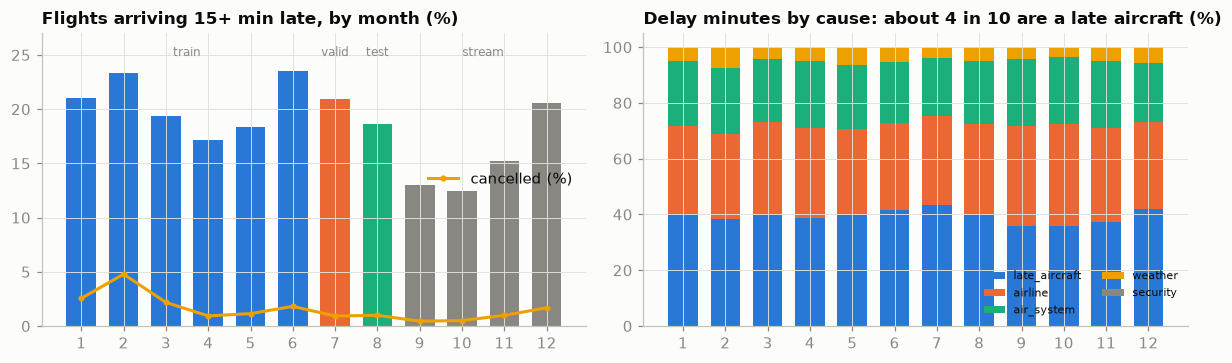

In [6]:
operated = (fl.cancelled.values == 0) & (fl.diverted.values == 0)
fl["late"] = (fl.arr_delay >= DELAY_MIN).astype(np.int8)            # only meaningful where operated
monthly = pd.DataFrame({"hit_rate": fl.late[operated].groupby(fl.month[operated]).mean(),
                        "cancelled": fl.groupby("month").cancelled.mean(), "diverted": fl.groupby("month").diverted.mean()})
cause = fl.groupby("month")[CAUSES].sum()
cause_share = cause.div(cause.sum(axis=1), axis=0)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
ax = axes[0]
colors = [SERIES[0] if m in TRAIN_MONTHS else SERIES[1] if m == VALID_MONTH else SERIES[2] if m == TEST_MONTH else MUTED
          for m in monthly.index]
ax.bar(monthly.index, monthly.hit_rate * 100, color=colors, width=0.7)
ax.plot(monthly.index, monthly.cancelled * 100, "-o", ms=3, lw=2, color=SERIES[3], label="cancelled (%)")
for x, lab_ in [(3.5, "train"), (7, "valid"), (8, "test"), (10.5, "stream")]:
    ax.text(x, monthly.hit_rate.max() * 100 * 1.06, lab_, color=MUTED, fontsize=8, ha="center")
ax.set_ylim(0, monthly.hit_rate.max() * 100 * 1.15); ax.set_xticks(range(1, 13)); ax.legend(loc="center right")
ax.set_title("Flights arriving 15+ min late, by month (%)")
ax = axes[1]
bottom = np.zeros(12)
for c, color in zip(CAUSES, SERIES + [MUTED]):
    ax.bar(cause_share.index, cause_share[c] * 100, bottom=bottom, color=color, width=0.7, label=c.replace("_delay", ""))
    bottom += cause_share[c].values * 100
ax.set_xticks(range(1, 13)); ax.legend(fontsize=7, loc="lower right", ncol=2)
ax.set_title("Delay minutes by cause: about 4 in 10 are a late aircraft (%)")
plt.tight_layout()
year_share = cause.sum() / cause.sum().sum()
print("hit rate by month:", " ".join(f"{m}:{v:.1%}" for m, v in monthly.hit_rate.items()))
print("cancelled by month:", " ".join(f"{m}:{v:.1%}" for m, v in monthly.cancelled.items()))
print(f"hit rate (operated flights): {fl.late[operated].mean():.1%} · mean arrival delay {fl.arr_delay[operated].mean():.1f} min, "
      f"median {fl.arr_delay[operated].median():.0f} · delay minutes by cause: "
      + ", ".join(f"{c.replace('_delay', '')} {v:.1%}" for c, v in year_share.items()))
lead_cause = cause_share.idxmax(axis=1)
print(f"late-aircraft share of delay minutes by month: {cause_share.late_aircraft_delay.min():.1%}–{cause_share.late_aircraft_delay.max():.1%} · "
      f"largest cause in {(lead_cause == 'late_aircraft_delay').sum()} of 12 months; otherwise: "
      + ", ".join(f"month {m} {c} {cause_share.loc[m, c]:.1%} vs late aircraft {cause_share.loc[m, 'late_aircraft_delay']:.1%}"
                  for m, c in lead_cause[lead_cause != "late_aircraft_delay"].items()))
filled = fl.loc[operated, CAUSES].notna().any(axis=1).values
print(f"cause columns filled ⇔ arrival delay ≥ 15: {np.mean(filled == (fl.arr_delay.values[operated] >= 15)):.2%} of operated flights · "
      f"causes sum to the arrival delay: {np.mean(np.isclose(fl.loc[operated, CAUSES].sum(axis=1).values[filled], fl.arr_delay.values[operated][filled])):.2%} · "
      f"cancellations by reason: {fl.cancel_reason.value_counts().to_dict()} (A carrier, B weather, C air system, D security)")

Two things to carry forward. The hit rate is seasonal: 23 % in February and June, 12–13 % in September and October. And **about four in ten delay minutes are a late aircraft**, by the carriers' own attribution: the largest cause in every month but October, when their own causes edge ahead (36.3 % against 36.0 %). Propagation is the biggest single cause in the data.

**The network.** Airports are nodes; a route is a directed edge carrying its flights and carriers; carriers link to the airports they serve. Built from the training months only.

In [7]:
train_rows = np.isin(fl.month.values, TRAIN_MONTHS)
routes = (fl.loc[train_rows, ["origin", "dest", "airline"]].groupby(["origin", "dest", "airline"], observed=True)
            .size().rename("flights").reset_index())
G = nx.DiGraph()
for (o, d), g in routes.groupby(["origin", "dest"], observed=True):
    G.add_edge(o, d, flights=int(g.flights.sum()), carriers=tuple(g.airline.astype(str)))
for (a, o), n in routes.groupby(["airline", "origin"], observed=True).flights.sum().items():
    G.add_edge(f"carrier:{a}", o, flights=int(n), kind="serves")
apt = G.subgraph([n for n in G if not str(n).startswith("carrier:")])
dep = (fl.loc[train_rows, ["origin", "dep_delay", "late"]].assign(late=lambda d: d.late.where(operated[train_rows]))
          .groupby("origin", observed=True).agg(departures=("dep_delay", "size"), dep_delay=("dep_delay", "mean"), late=("late", "mean")))
hubs = dep.assign(routes_out=pd.Series(dict(apt.out_degree())),
                  carriers=pd.Series({a: sum(1 for p in G.predecessors(a) if str(p).startswith("carrier:")) for a in apt}),
                  betweenness=pd.Series(nx.betweenness_centrality(apt, seed=SEED))).sort_values("departures", ascending=False)
HUBS = list(hubs.index[:10])
print(f"airport graph: {apt.number_of_nodes()} airports · {apt.number_of_edges():,} routes · "
      f"{G.number_of_edges() - apt.number_of_edges():,} carrier–airport links · strongly connected: {nx.is_strongly_connected(apt)} · "
      f"the 10 busiest airports carry {hubs.departures.head(10).sum() / hubs.departures.sum():.0%} of departures")
hubs.head(8).style.format({"departures": "{:,}", "dep_delay": "{:.1f}", "late": "{:.1%}", "betweenness": "{:.3f}"})

airport graph: 322 airports · 4,533 routes · 1,251 carrier–airport links · strongly connected: True · the 10 busiest airports carry 37% of departures


,departures,dep_delay,late,routes_out,carriers,betweenness
origin,,,,,,
ATL,"186,135",9.6,16.8%,168,11,0.178
ORD,"151,692",15.9,26.9%,160,12,0.156
DFW,"133,816",13.9,25.3%,148,11,0.169
DEN,"105,623",12.7,23.9%,138,11,0.116
LAX,"105,034",10.2,21.2%,79,13,0.028
IAH,"81,773",12.6,23.5%,117,9,0.062
PHX,"80,984",8.9,19.6%,78,12,0.027
SFO,"78,290",10.8,20.9%,77,11,0.048


Ten airports carry 37 % of departures, and four (Atlanta, Chicago O'Hare, Dallas/Fort Worth, Denver) lead on traffic and betweenness alike: most shortest routes pass through them.

**How delay travels.** Delay rides on the **aircraft rotation**, the next flight of the same tail number. We sort every flown leg by aircraft and scheduled departure, the backbone of Section 4's features too. The `Events` helper keeps event times sorted per airport with running sums, so "how late were departures here in the hour before 14:00?" is one binary search.

In [8]:
SHIFT, PAD = np.uint32(1 << 20), 10_000          # minutes of the year fit in 20 bits; the group id sits above them

def _key(g, t):
    return g.astype(np.uint32) * SHIFT + (t + PAD).astype(np.uint32)

class Events:
    """Event times sorted by (group, time) with running sums: count, mean and late share in any window, in O(log n)."""
    def __init__(self, g, t, v):
        ok = ~np.isnan(t)
        key = _key(g[ok], t[ok]); order = np.argsort(key, kind="stable")
        self.key, v = key[order], v[ok][order].astype(np.int64)       # delays are whole minutes: exact integer sums
        self.csum = np.r_[0, np.cumsum(v)].astype(np.int32)
        self.c15 = np.r_[0, np.cumsum(v >= DELAY_MIN)].astype(np.int32)
    def _pos(self, g, t):
        return np.searchsorted(self.key, _key(g, t), side="left")
    def window(self, g, t_from, t_to):
        lo, hi = self._pos(g, t_from), self._pos(g, t_to); n = hi - lo
        with np.errstate(invalid="ignore", divide="ignore"):
            mean = np.where(n > 0, (self.csum[hi].astype(np.int64) - self.csum[lo]) / n, np.nan)
            late = np.where(n > 0, (self.c15[hi] - self.c15[lo]) / n, np.nan)
        return n.astype(np.float32), mean.astype(np.float32), late.astype(np.float32)
    def count_before(self, g, t):
        return self._pos(g, t) - np.searchsorted(self.key, g.astype(np.uint32) * SHIFT, side="left")

def build_state():
    """Everything the feature function looks up: airport event streams, a network index and the rotation table."""
    S = {"o": fl.origin.cat.codes.values.astype(np.int16), "d": fl.dest.cat.codes.values.astype(np.int16)}
    left = ~np.isnan(fl.adep_utc.values)
    S["dep"] = Events(S["o"], fl.adep_utc.values, fl.dep_delay.values)                     # departures that happened
    S["arr"] = Events(S["d"], fl.aarr_utc.values, fl.arr_delay.values)                     # arrivals that happened
    S["sch"] = Events(S["o"][left], fl.sdep_utc.values[left], np.zeros(left.sum(), np.float32))
    mins = fl.adep_utc.values[left].astype(np.int64) + 2000                                # network-wide, per minute
    S["net_n"] = np.r_[0, np.cumsum(np.bincount(mins, minlength=545_000))].astype(np.int32)
    S["net_s"] = np.r_[0, np.cumsum(np.bincount(mins, weights=fl.dep_delay.values[left], minlength=545_000))]
    idx = np.flatnonzero((fl.cancelled.values == 0) & fl.tail_no.notna().values)          # rotations: flown legs
    tc = fl.tail_no.cat.codes.values[idx].astype(np.int64)
    key = (tc << 20) + (fl.sdep_utc.values[idx] + PAD).astype(np.int64)
    order = np.argsort(key, kind="stable"); idx = idx[order]
    R = {"key_sd": key[order], "tl": tc[order].astype(np.int32), "o": S["o"][idx], "d": S["d"][idx]}
    for c in ["sdep_utc", "sarr_utc", "adep_utc", "aarr_utc", "dep_delay", "arr_delay"]:
        R[c] = fl[c].values[idx]
    same = np.r_[False, R["tl"][1:] == R["tl"][:-1]]
    R["turn"] = np.where(same, R["sdep_utc"] - np.r_[np.nan, R["sarr_utc"][:-1]], np.nan).astype(np.float32)
    R["S"] = np.cumsum(np.nan_to_num(np.clip(R["turn"] - MIN_TURN_MIN, 0, None)).astype(np.int64)).astype(np.int32)
    ad = pd.Series(R["adep_utc"]).groupby(R["tl"]).cummax().fillna(1 - PAD).values
    R["key_ad"] = (R["tl"].astype(np.int64) << 20) + (ad + PAD).astype(np.int64)
    S["R"] = R
    return S

t0 = time.time()
STATE = build_state(); R = STATE["R"]
print(f"state built in {time.time()-t0:.0f}s · {len(R['tl']):,} flown legs on {fl.tail_no.nunique():,} aircraft · "
      f"planned turn negative (aircraft swaps or errors) on {np.mean(R['turn'] < 0):.1%} of consecutive legs")

state built in 6s · 5,728,099 flown legs on 4,897 aircraft · planned turn negative (aircraft swaps or errors) on 1.0% of consecutive legs


hop,0,1,2,3,4,5
still flying,1.000000,0.930000,0.740000,0.48,0.23,0.08
mean dep delay,118.550003,60.349998,37.939999,27.50,25.85,24.68
share 15+ late,1.000000,0.600000,0.460000,0.36,0.37,0.35


after an on-time hub departure, next legs 15+ late: [0.09, 0.14, 0.16] · inbound 30–59 min late: next departure 15+ late on 99% of turns ≤ 45 min, 61% of 61–90 min, 20% of 91–180 min


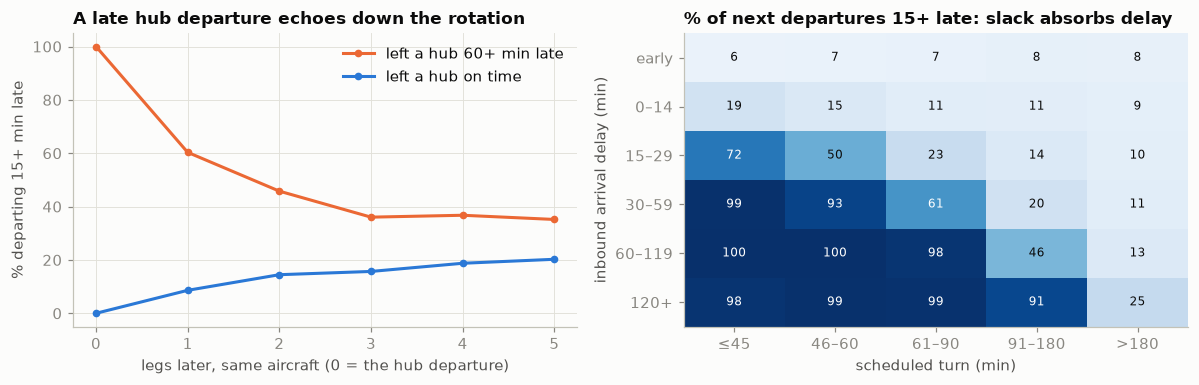

In [9]:
link = np.flatnonzero((R["turn"] > 0) & (R["turn"] < 12 * 60))    # same aircraft, same duty period
link = link[~np.isnan(R["arr_delay"][link - 1])]                    # the inbound leg landed where planned
INB_BINS, INB_LAB = [0, 15, 30, 60, 120], ["early", "0–14", "15–29", "30–59", "60–119", "120+"]
TURN_BINS, TURN_LAB = [45, 60, 90, 180], ["≤45", "46–60", "61–90", "91–180", ">180"]
cell = np.digitize(R["arr_delay"][link - 1], INB_BINS, right=False) * 5 + np.digitize(R["turn"][link], TURN_BINS, right=True)
heat = pd.DataFrame((np.bincount(cell, weights=R["dep_delay"][link] >= DELAY_MIN, minlength=30) /
                     np.maximum(np.bincount(cell, minlength=30), 1)).reshape(6, 5), index=INB_LAB, columns=TURN_LAB)

hub_codes = np.isin(R["o"], [AIRPORTS.index(h) for h in HUBS])
hop = {}
for name, start in [("left a hub 60+ min late", np.flatnonzero(hub_codes & (R["dep_delay"] >= 60))),
                    ("left a hub on time", np.flatnonzero(hub_codes & (R["dep_delay"] <= 0)))]:
    rows_ = []
    for k in range(6):
        j = start + k; ok = j < len(R["tl"]); j, s0 = j[ok], start[ok]
        ok = (R["tl"][j] == R["tl"][s0]) & (R["sdep_utc"][j] - R["sdep_utc"][s0] < 18 * 60)
        rows_.append((k, ok.mean() * len(s0) / len(start), np.mean(R["dep_delay"][j[ok]]), np.mean(R["dep_delay"][j[ok]] >= DELAY_MIN)))
    hop[name] = pd.DataFrame(rows_, columns=["hop", "still flying", "mean dep delay", "share 15+ late"]).set_index("hop")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
ax = axes[0]
for (name, h), color in zip(hop.items(), [SERIES[1], SERIES[0]]):
    ax.plot(h.index, h["share 15+ late"] * 100, "-o", ms=4, lw=2, color=color, label=name)
ax.set_xlabel("legs later, same aircraft (0 = the hub departure)"); ax.set_ylabel("% departing 15+ min late")
ax.set_title("A late hub departure echoes down the rotation"); ax.legend()
ax = axes[1]
im = ax.imshow(heat.values * 100, cmap="Blues", vmin=0, vmax=100, aspect="auto")
ax.set_xticks(range(heat.shape[1]), heat.columns); ax.set_yticks(range(heat.shape[0]), heat.index); ax.grid(False)
for i in range(heat.shape[0]):
    for j in range(heat.shape[1]):
        v = heat.values[i, j] * 100
        ax.text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=8, color="white" if v > 60 else INK)
ax.set_xlabel("scheduled turn (min)"); ax.set_ylabel("inbound arrival delay (min)")
ax.set_title("% of next departures 15+ late: slack absorbs delay")
plt.tight_layout()
display(hop["left a hub 60+ min late"].round(2).T)
print(f"after an on-time hub departure, next legs 15+ late: {hop['left a hub on time']['share 15+ late'].iloc[1:4].round(2).tolist()} · "
      f"inbound 30–59 min late: next departure 15+ late on {heat.loc['30–59', '≤45']:.0%} of turns ≤ 45 min, "
      f"{heat.loc['30–59', '61–90']:.0%} of 61–90 min, {heat.loc['30–59', '91–180']:.0%} of 91–180 min")

This is the mechanism behind the board question. When an aircraft leaves one of the ten busiest airports an hour or more late, its next flight departs 15+ minutes late 60 % of the time, against 9 % after an on-time departure; two and three legs later, still 46 % and 36 % (against 14 % and 16 %). The right panel shows the brake: an inbound aircraft 30–59 minutes late delays the next departure on 99 % of turns of 45 minutes or less, and on one in five when the schedule allows 91–180. Rotation slack is the airline's shock absorber, fixed by the schedule before the day starts.

# Part B — The given model

*Sections 4–6: read them, then package the code unchanged and reproduce its numbers (C2). You do not change the method.*

## 4 · Two hours before departure: features, model and the network ablation

*Part B · Given model · package `features`, `flights_in`, `f1_threshold`, `scores` and `fit_eval` unchanged and reproduce the numbers (C2); E1 re-runs the ablation.*

One rule for every feature: **use only what the movement messages have reported by τ = scheduled departure − 2 h.** Three families:

- **Schedule**: hour, weekday, block time, distance, carrier, origin, destination.
- **Airport state**: the last hour's departures from the origin and arrivals at the destination (count, mean delay, share 15+ late), and origin flights that should have left by τ and have not.
- **Upstream network**: the inbound aircraft's status at τ (on the ground upstream, airborne, arrived), its known delay or how overdue it is, its projected slack, the delay last seen along the rotation carried forward through the slack in between (`prop_delay`), the upstream airport's last hour, a network delay index.

In [10]:
def features(rows, H):
    """Features for flights `rows` (positions in fl) as known H minutes before each scheduled departure."""
    S, R = STATE, STATE["R"]
    sd = fl.sdep_utc.values[rows]; tau = sd - H
    X = pd.DataFrame({c: fl[c].values[rows] for c in ["hour", "dow", "sched_time", "distance", "airline", "origin", "dest"]}, index=rows)
    oc, dc = S["o"][rows], S["d"][rows]
    X["orig_dep_n"], X["orig_dep_mean"], X["orig_dep_late"] = S["dep"].window(oc, tau - LOOKBACK_MIN, tau)
    X["dest_arr_n"], X["dest_arr_mean"], X["dest_arr_late"] = S["arr"].window(dc, tau - LOOKBACK_MIN, tau)
    X["orig_overdue_n"] = (S["sch"].count_before(oc, tau) - S["dep"].count_before(oc, tau)).astype(np.float32)   # cancellations assumed known by their scheduled time
    lo, hi = (tau - LOOKBACK_MIN).astype(np.int64) + 2000, tau.astype(np.int64) + 2000
    n = S["net_n"][hi] - S["net_n"][lo]
    X["net_dep_mean"] = np.where(n > 0, (S["net_s"][hi] - S["net_s"][lo]) / np.maximum(n, 1), np.nan).astype(np.float32)
    # ---- the inbound aircraft: last flown leg of this tail scheduled before this flight ----
    tl = fl.tail_no.cat.codes.values[rows].astype(np.int64)
    prev = np.searchsorted(R["key_sd"], (tl << 20) + (sd + PAD).astype(np.int64), side="left") - 1
    ok = fl.tail_no.notna().values[rows] & (prev >= 0) & (R["tl"][np.clip(prev, 0, None)] == tl)
    prev = np.clip(prev, 0, None)
    turn = sd - R["sarr_utc"][prev]
    ok &= (turn > -60) & (turn < 12 * 60)                       # same duty period; swaps can make the planned turn slightly negative
    dep_known, arr_known = ok & (R["adep_utc"][prev] <= tau), ok & (R["aarr_utc"][prev] <= tau)
    overdue = np.clip(tau - R["sdep_utc"][prev], 0, None)
    known = np.where(arr_known, R["arr_delay"][prev], np.where(dep_known, R["dep_delay"][prev], overdue))
    X["sched_turn"] = np.where(ok, turn, np.nan).astype(np.float32)
    X["inb_status"] = np.select([~ok, arr_known, dep_known], [0, 3, 2], 1).astype(np.int8)   # 0 none · 1 on ground upstream · 2 airborne · 3 arrived
    X["inb_dep_delay"] = np.where(dep_known, R["dep_delay"][prev], np.nan).astype(np.float32)
    X["inb_arr_delay"] = np.where(arr_known, R["arr_delay"][prev], np.nan).astype(np.float32)
    X["inb_overdue"] = np.where(ok & ~dep_known, overdue, np.nan).astype(np.float32)
    X["inb_proj_slack"] = np.where(ok, turn - known, np.nan).astype(np.float32)
    # ---- the last leg of this rotation that has departed by tau, and the delay it carries forward ----
    j = np.minimum(np.searchsorted(R["key_ad"], (tl << 20) + (tau + PAD).astype(np.int64), side="right") - 1, prev)
    j_ok = ok & (j >= 0) & (R["tl"][np.clip(j, 0, None)] == tl)
    j = np.clip(j, 0, None); j_ok &= (sd - R["sdep_utc"][j]) < 18 * 60
    seen = np.where(R["aarr_utc"][j] <= tau, R["arr_delay"][j], R["dep_delay"][j])
    slack = (R["S"][prev] - R["S"][j]) + np.clip(np.nan_to_num(turn) - MIN_TURN_MIN, 0, None)
    X["chain_hops"] = np.where(j_ok, prev - j + 1, np.nan).astype(np.float32)
    X["prop_delay"] = np.where(j_ok, np.clip(seen - slack, 0, None), np.nan).astype(np.float32)
    _, m_, late_ = S["dep"].window(R["o"][prev], tau - LOOKBACK_MIN, tau)          # the airport the aircraft comes from
    X["up_dep_mean"] = np.where(ok, m_, np.nan).astype(np.float32); X["up_dep_late"] = np.where(ok, late_, np.nan).astype(np.float32)
    X["inb_from"] = np.where(ok, R["o"][prev], -1).astype(np.int16)                 # for briefs, not a model feature
    return X

SCHEDULE = ["hour", "dow", "sched_time", "distance", "airline", "origin", "dest"]
AIRPORT = ["orig_dep_n", "orig_dep_mean", "orig_dep_late", "dest_arr_n", "dest_arr_mean", "dest_arr_late", "orig_overdue_n"]
NETWORK = ["net_dep_mean", "sched_turn", "inb_status", "inb_dep_delay", "inb_arr_delay", "inb_overdue", "inb_proj_slack",
           "chain_hops", "prop_delay", "up_dep_mean", "up_dep_late"]

rng = np.random.default_rng(SEED)
def flights_in(months, n=None, mask=operated):
    ix = np.flatnonzero(mask & np.isin(fl.month.values, months))
    return ix if n is None or n >= len(ix) else np.sort(rng.choice(ix, size=n, replace=False))

tr, va, te = flights_in(TRAIN_MONTHS, N_TRAIN), flights_in([VALID_MONTH], N_VALID), flights_in([TEST_MONTH])
t0 = time.time()
X_tr, X_va, X_te = (features(r, HORIZON_MIN) for r in (tr, va, te))
y = fl.arr_delay.values
y_tr, y_va, y_te = y[tr], y[va], y[te]
print(f"train {len(tr):,} flights (Jan–Jun sample) · valid {len(va):,} (July sample) · test {len(te):,} (all operated August flights) · "
      f"features in {time.time()-t0:.0f}s · hit rate train {np.mean(y_tr >= DELAY_MIN):.1%}, test {np.mean(y_te >= DELAY_MIN):.1%}")
X_te[NETWORK].describe().T[["count", "mean", "50%", "max"]].round(1)

train 200,000 flights (Jan–Jun sample) · valid 150,000 (July sample) · test 503,956 (all operated August flights) · features in 1s · hit rate train 20.5%, test 18.7%


,count,mean,50%,max
net_dep_mean,503956.0,7.7,5.4,73.2
sched_turn,472380.0,139.7,52.0,719.0
inb_status,503956.0,1.9,2.0,3.0
inb_dep_delay,391835.0,6.2,-2.0,659.0
inb_arr_delay,103084.0,8.5,-4.0,508.0
inb_overdue,80545.0,7.7,0.0,665.0
inb_proj_slack,472380.0,134.6,52.0,760.0
chain_hops,469496.0,1.2,1.0,8.0
prop_delay,469496.0,2.1,0.0,286.0
up_dep_mean,401833.0,8.6,3.1,1110.0


LightGBM, twice per feature set: a classifier for the 15-minute flag (threshold chosen on July to maximise F1, then frozen) and a median regressor for the minutes (MAE). The ablation adds one family at a time. Two reference rows: a constant (the training median) and the **propagation rule** "flag if `prop_delay` ≥ 15", Section 3's mechanism without a model.

In [11]:
LGB_PARAMS = dict(n_estimators=150, learning_rate=0.08, num_leaves=31, min_child_samples=100, subsample=0.8,
                  subsample_freq=1, colsample_bytree=0.8, random_state=SEED, n_jobs=N_JOBS, verbose=-1)

def f1_threshold(y_true, p):
    pr, rc, th = precision_recall_curve(y_true, p)
    return float(th[np.argmax((2 * pr * rc / np.maximum(pr + rc, 1e-9))[:-1])])

def scores(y_min, flag, p=None):
    yb = y_min >= DELAY_MIN
    return {"F1": f1_score(yb, flag), "precision": precision_score(yb, flag), "recall": recall_score(yb, flag),
            "AUPRC": average_precision_score(yb, p) if p is not None else np.nan}

def fit_eval(cols, name, regress=True):
    t1 = time.time()
    clf = lgb.LGBMClassifier(**LGB_PARAMS).fit(X_tr[cols], y_tr >= DELAY_MIN)
    thr = f1_threshold(y_va >= DELAY_MIN, clf.predict_proba(X_va[cols])[:, 1])
    p = clf.predict_proba(X_te[cols])[:, 1]
    reg = lgb.LGBMRegressor(objective="l1", **LGB_PARAMS).fit(X_tr[cols], y_tr) if regress else None
    minutes = reg.predict(X_te[cols]) if regress else None
    res = {"model": name, "MAE (min)": mean_absolute_error(y_te, minutes) if regress else np.nan,
           **scores(y_te, p >= thr, p), "threshold": thr, "fit_s": time.time() - t1}
    return clf, (reg, minutes), thr, p, res

rows = [{"model": "constant: training median", "MAE (min)": mean_absolute_error(y_te, np.full(len(y_te), np.median(y_tr)))},
        {"model": "propagation rule: prop_delay ≥ 15", **scores(y_te, np.nan_to_num(X_te.prop_delay.values) >= DELAY_MIN)}]
clf_s, reg_s, thr_s, p_s, r_s = fit_eval(SCHEDULE, "schedule only")
clf_a, reg_a, thr_a, p_a, r_a = fit_eval(SCHEDULE + AIRPORT, "+ airport state")
FEATS = SCHEDULE + AIRPORT + NETWORK
clf, (reg, minutes_te), THR_F1, p_te, r_n = fit_eval(FEATS, "+ upstream network")
ablation = pd.DataFrame(rows + [r_s, r_a, r_n]).set_index("model")
ablation.style.format({"MAE (min)": "{:.2f}", "F1": "{:.3f}", "precision": "{:.1%}", "recall": "{:.1%}", "AUPRC": "{:.3f}",
                       "threshold": "{:.2f}", "fit_s": "{:.0f}"}, na_rep="–")

,MAE (min),F1,precision,recall,AUPRC,threshold,fit_s
model,,,,,,,
constant: training median,19.17,–,–,–,–,–,–
propagation rule: prop_delay ≥ 15,–,0.289,80.7%,17.6%,–,–,–
schedule only,18.83,0.361,24.6%,68.2%,0.273,0.18,22
+ airport state,18.39,0.391,29.4%,58.5%,0.357,0.20,24
+ upstream network,15.96,0.520,55.1%,49.3%,0.588,0.28,30


top features by gain share: inb_proj_slack 31%, prop_delay 13%, origin 12%, dest 11% · by family: schedule 27%, airport 15%, network 58%


,30,60,120,240,480
F1,0.592,0.561,0.522,0.434,0.388
AUPRC,0.667,0.638,0.588,0.473,0.381


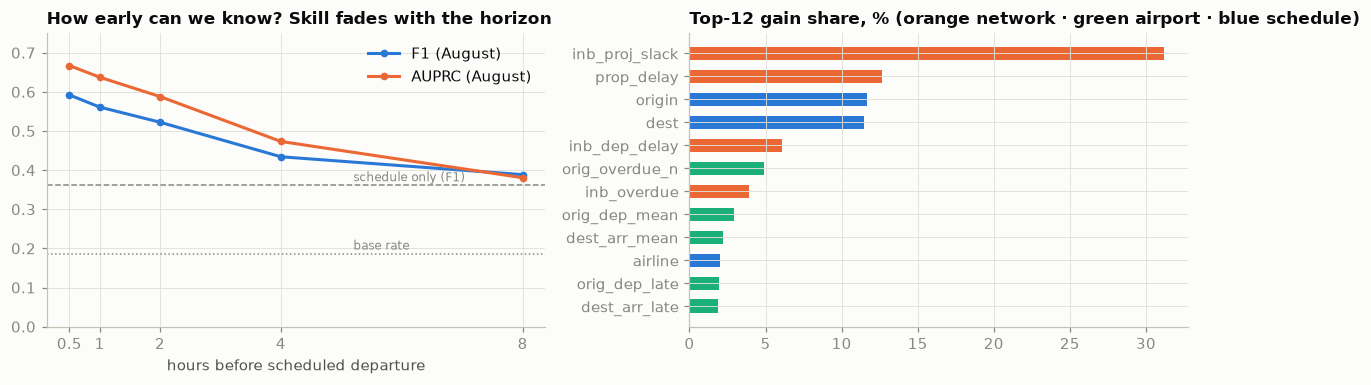

In [12]:
te_h = np.sort(rng.choice(te, size=N_VALID, replace=False))                 # an August sample is enough for the curve
p_h = clf.predict_proba(X_te.loc[te_h, FEATS])[:, 1]
horizon = {HORIZON_MIN: (f1_score(y[te_h] >= DELAY_MIN, p_h >= THR_F1), average_precision_score(y[te_h] >= DELAY_MIN, p_h))}
for H in HORIZONS:
    if H == HORIZON_MIN:
        continue
    Xh_tr, Xh_va, Xh_te = (features(r, H) for r in (tr, va, te_h))
    c_h = lgb.LGBMClassifier(**LGB_PARAMS).fit(Xh_tr[FEATS], y_tr >= DELAY_MIN)
    p_h = c_h.predict_proba(Xh_te[FEATS])[:, 1]
    th_h = f1_threshold(y_va >= DELAY_MIN, c_h.predict_proba(Xh_va[FEATS])[:, 1])
    horizon[H] = (f1_score(y[te_h] >= DELAY_MIN, p_h >= th_h), average_precision_score(y[te_h] >= DELAY_MIN, p_h))
del Xh_tr, Xh_va, Xh_te
horizon = pd.DataFrame(horizon, index=["F1", "AUPRC"]).T.sort_index()

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
ax = axes[0]
ax.plot(horizon.index / 60, horizon.F1, "-o", ms=4, lw=2, color=SERIES[0], label="F1 (August)")
ax.plot(horizon.index / 60, horizon.AUPRC, "-o", ms=4, lw=2, color=SERIES[1], label="AUPRC (August)")
ax.axhline(r_s["F1"], color=MUTED, ls="--", lw=1); ax.text(5.2, r_s["F1"] + 0.01, "schedule only (F1)", color=MUTED, fontsize=8)
ax.axhline(np.mean(y_te >= DELAY_MIN), color=MUTED, ls=":", lw=1); ax.text(5.2, np.mean(y_te >= DELAY_MIN) + 0.01, "base rate", color=MUTED, fontsize=8)
ax.set_xlabel("hours before scheduled departure"); ax.set_xticks(horizon.index / 60, [f"{h / 60:g}" for h in horizon.index]); ax.set_ylim(0, 0.75)
ax.set_title("How early can we know? Skill fades with the horizon"); ax.legend(loc="upper right")
ax = axes[1]
gain = pd.Series(clf.booster_.feature_importance("gain"), index=FEATS); gain = gain / gain.sum()
imp = gain.sort_values(ascending=False).head(12)
colors = [SERIES[1] if f in NETWORK else SERIES[2] if f in AIRPORT else SERIES[0] for f in imp.index]
ax.barh(imp.index[::-1], imp.values[::-1] * 100, color=colors[::-1], height=0.6)
ax.set_title("Top-12 gain share, % (orange network · green airport · blue schedule)")
plt.tight_layout()
print("top features by gain share:", ", ".join(f"{f} {v:.0%}" for f, v in imp.head(4).items()),
      f"· by family: schedule {gain[SCHEDULE].sum():.0%}, airport {gain[AIRPORT].sum():.0%}, network {gain[NETWORK].sum():.0%}")
horizon.round(3).T

Read the ablation from the top. The schedule alone earns an F1 of 0.36: evening departures from busy hubs run late, little more. The airport's last hour adds three points. **Upstream-network context is the step change**: F1 0.52, AUPRC from 0.36 to 0.59, MAE from 18.4 to 16.0 minutes (19.2 for the constant), with the inbound aircraft's projected slack and the delay carried along the rotation on top. Part of that gain is optimistic, because the tail numbers record swaps made after τ (quirk 5). The propagation rule alone is precise (81 %) but finds only 18 % of hit flights: it sees aircraft already late upstream, which no schedule can.

The horizon curve answers the second half of the board question: F1 0.59 thirty minutes out, 0.52 at two hours, 0.43 at four and 0.39 at eight, close to the schedule-only 0.36, because most aircraft have not yet flown that day. **The warning builds over the last four hours, as the rotation reveals itself.**

## 5 · The operating point: what the OCC can work in an hour

*Part B · Given model · package `operating`; C3 asks you to own the costs and capacity, and S2 starts from the brief.*

Acting on a flag costs `ACTION_COST_USD` and saves `AVOIDED_COST_USD` if the flight is in fact hit (both assumptions); the desk works at most `OCC_CAPACITY_PER_HOUR` flags an hour. We choose the threshold on all of July so that the 95th-percentile hour stays within capacity, then freeze it for August.

July: value-maximising threshold 0.16 without the capacity limit (flags 38.8% of operated July flights, 6,392 a day), 0.72 within it · August hours over capacity: 12 of 750


,threshold,flags_per_day,p95_flags_per_hour,precision,recall,net_value_per_day
model at chosen threshold,0.72,812,108,89.8%,24.2%,"$606,874"
propagation rule,–,661,–,80.7%,17.6%,"$434,413"


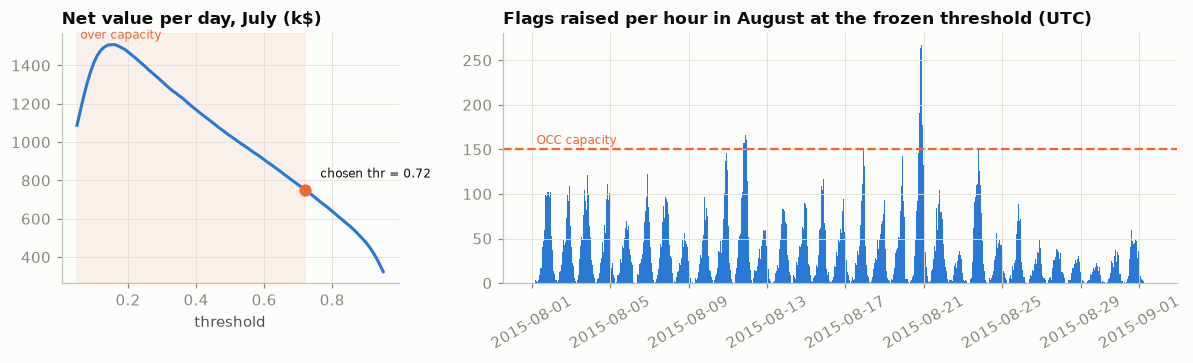

In [13]:
july = flights_in([VALID_MONTH])                                                  # all of July: capacity is counted per hour
p_jul = clf.predict_proba(features(july, HORIZON_MIN)[FEATS])[:, 1]
hour_jul = ((fl.sdep_utc.values[july] - HORIZON_MIN) // 60).astype(np.int64)      # the hour in which the flag is raised
hour_te = ((fl.sdep_utc.values[te] - HORIZON_MIN) // 60).astype(np.int64)
hit_jul, hit_te = y[july] >= DELAY_MIN, y_te >= DELAY_MIN

def operating(p, hit, hours, thr):
    flag = p >= thr
    _, h_ix = np.unique(hours, return_inverse=True); days = (h_ix.max() + 1) / 24
    return {"threshold": thr, "flags_per_day": flag.sum() / days,
            "p95_flags_per_hour": np.quantile(np.bincount(h_ix, weights=flag), 0.95),
            "precision": hit[flag].mean(), "recall": flag[hit].mean(),
            "net_value_per_day": (AVOIDED_COST_USD * (flag & hit).sum() - ACTION_COST_USD * flag.sum()) / days}

grid = pd.DataFrame([operating(p_jul, hit_jul, hour_jul, t) for t in np.linspace(0.05, 0.95, 91)])
feasible = grid[grid.p95_flags_per_hour <= OCC_CAPACITY_PER_HOUR]
THR_OP = float(feasible.loc[feasible.net_value_per_day.idxmax(), "threshold"])
unconstrained = float(grid.loc[grid.net_value_per_day.idxmax(), "threshold"])
op_te = operating(p_te, hit_te, hour_te, THR_OP)
flags_hour = pd.Series(p_te >= THR_OP).groupby(hour_te).sum()

fig, axes = plt.subplots(1, 2, figsize=(11, 3.4), gridspec_kw={"width_ratios": [1, 2]})
ax = axes[0]
ax.plot(grid.threshold, grid.net_value_per_day / 1e3, lw=2, color=SERIES[0])
ax.axvspan(grid.threshold.min(), feasible.threshold.min(), color=SERIES[1], alpha=0.08)
ax.text(grid.threshold.min() + 0.01, grid.net_value_per_day.max() / 1e3 * 1.02, "over capacity", color=SERIES[1], fontsize=8)
ax.plot([THR_OP], [feasible.net_value_per_day.max() / 1e3], "o", color=SERIES[1], ms=7)
ax.annotate(f"chosen thr = {THR_OP:.2f}", (THR_OP, feasible.net_value_per_day.max() / 1e3), xytext=(10, 8), textcoords="offset points", fontsize=8)
ax.set_title("Net value per day, July (k$)"); ax.set_xlabel("threshold")
ax = axes[1]
t_hours = pd.to_datetime("2015-01-01") + pd.to_timedelta(flags_hour.index * 60, unit="min")
ax.bar(t_hours, flags_hour.values, width=1 / 24, color=SERIES[0])
ax.axhline(OCC_CAPACITY_PER_HOUR, color=SERIES[1], lw=1.5, ls="--")
ax.text(t_hours[3], OCC_CAPACITY_PER_HOUR * 1.04, "OCC capacity", color=SERIES[1], fontsize=8)
ax.set_title("Flags raised per hour in August at the frozen threshold (UTC)"); ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
rule_flag = np.nan_to_num(X_te.prop_delay.values) >= DELAY_MIN
summary = pd.DataFrame({"model at chosen threshold": op_te,
                        "propagation rule": {"flags_per_day": rule_flag.sum() / 31, "precision": hit_te[rule_flag].mean(), "recall": rule_flag[hit_te].mean(),
                                             "net_value_per_day": (AVOIDED_COST_USD * (rule_flag & hit_te).sum() - ACTION_COST_USD * rule_flag.sum()) / 31}})
print(f"July: value-maximising threshold {unconstrained:.2f} without the capacity limit (flags {np.mean(p_jul >= unconstrained):.1%} of "
      f"operated July flights, {grid.loc[grid.net_value_per_day.idxmax(), 'flags_per_day']:,.0f} a day), {THR_OP:.2f} within it · "
      f"August hours over capacity: {(flags_hour > OCC_CAPACITY_PER_HOUR).sum()} of {len(flags_hour)}")
summary.T.style.format({"threshold": "{:.2f}", "flags_per_day": "{:,.0f}", "p95_flags_per_hour": "{:.0f}", "precision": "{:.1%}",
                        "recall": "{:.1%}", "net_value_per_day": "${:,.0f}"}, na_rep="–")

**What the controller sees.** The model as a network-state brief: August's worst hub-hour between noon and 20:00 local, and the departures two to four hours later that leave that hub or whose aircraft comes from it, scored as of the end of that hour. The brief is a deterministic template grounded in the scored table; it is the context an LLM gets in task S2, and the citation check it must pass.

In [14]:
aug = fl.month.values == TEST_MONTH
dh = fl.loc[aug & fl.origin.isin(HUBS).values & ~np.isnan(fl.adep_utc.values), ["origin", "adep_utc", "dep_delay"]]
dh["h"] = (dh.adep_utc // 60).astype(int)                                       # UTC hour of the actual departure
dh["local_h"] = (dh.h + dh.origin.map(UTC_OFFSET[True] / 60).astype(int)) % 24
hub_hours = (dh[dh.local_h.between(12, 19)].groupby(["origin", "h"], observed=True).dep_delay
             .agg(["mean", "size"]).query("size >= 40").sort_values("mean"))
hub, h_utc = hub_hours.index[-1]
T = (h_utc + 1) * 60                                                            # brief written at the end of that hour (UTC)
cand = np.flatnonzero(aug & (fl.sdep_utc.values >= T + 120) & (fl.sdep_utc.values < T + 240))
Xc = features(cand, fl.sdep_utc.values[cand] - T)                               # as known at T, each with its own horizon
hub_code = AIRPORTS.index(hub)
mask = (Xc.inb_from.values == hub_code) | (STATE["o"][cand] == hub_code)
cand, Xc = cand[mask], Xc[mask]
pc_ = clf.predict_proba(Xc[FEATS])[:, 1]
outcome = (np.nan_to_num(fl.arr_delay.values[cand]) >= DELAY_MIN) | (fl.cancelled.values[cand] == 1) | (fl.diverted.values[cand] == 1)
brief = pd.DataFrame({"flight": fl.airline.values[cand].astype(str) + fl.flight_number.values[cand].astype(str),   # index first, then
                      "route": fl.origin.values[cand].astype(str) + "→" + fl.dest.values[cand].astype(str),        # convert: 29 rows, not 5.8 M
                      "sched_local": [f"{v // 100:02d}:{v % 100:02d}" for v in fl.sched_dep.values[cand]],
                      "inbound_from": [AIRPORTS[i] if i >= 0 else "–" for i in Xc.inb_from.values],
                      "inbound_known_delay": Xc.inb_dep_delay.fillna(Xc.inb_overdue).values, "p_hit": pc_,
                      "flagged": pc_ >= THR_OP, "hit_outcome": outcome}).sort_values("p_hit", ascending=False).reset_index(drop=True)
t_local = pd.Timestamp("2015-01-01") + pd.Timedelta(minutes=T + UTC_OFFSET[True][hub])
lines = [f"NETWORK STATE {t_local:%d %b %Y %H:%M} local at {hub}: "
         f"departures in the last hour averaged {hub_hours['mean'].iloc[-1]:.0f} min late ({int(hub_hours['size'].iloc[-1])} flights). "
         f"{len(brief)} departures in the next 2–4 h depend on {hub}; {int(brief.flagged.sum())} flagged:"]
lines += [f"  [{r.flight} {r.route} {r.sched_local}] p={r.p_hit:.2f}, inbound from {r.inbound_from}" for r in brief[brief.flagged].head(6).itertuples()]
print("\n".join(lines))
cited = set(brief.flight[brief.flagged].head(6))
print(f"\ncitation check: {len(cited)} cited, all in the candidate table: {cited <= set(brief.flight)} · "
      f"outcome: {int(brief.hit_outcome.sum())} of {len(brief)} were hit; the flags caught {int((brief.flagged & brief.hit_outcome).sum())} "
      f"with {int((brief.flagged & ~brief.hit_outcome).sum())} false alarms")

NETWORK STATE 10 Aug 2015 20:00 local at ORD: departures in the last hour averaged 111 min late (45 flights). 29 departures in the next 2–4 h depend on ORD; 18 flagged:
  [DL1563 ATL→JAX 23:25] p=0.99, inbound from ORD
  [AA91 ORD→DFW 22:15] p=0.98, inbound from DFW
  [UA279 ANC→ORD 20:14] p=0.96, inbound from ORD
  [UA1110 ORD→MSP 22:25] p=0.96, inbound from LGA
  [UA1650 ORD→SEA 22:45] p=0.95, inbound from BOS
  [UA378 ORD→DEN 22:25] p=0.94, inbound from DEN

citation check: 6 cited, all in the candidate table: True · outcome: 13 of 29 were hit; the flags caught 11 with 7 false alarms


Read this as the business would. Without a capacity limit the July value peaks at a threshold of 0.16: at these costs a one-in-six chance of a hit is worth a call, and nearly two flights in five clear it. No desk can work that. Within 150 flags an hour the threshold rises to 0.72, and in August the OCC works about 810 flags a day, 9 in 10 real: a quarter of the flights that will be hit. The propagation rule flags fewer, less precisely. Twelve August hours still exceed capacity, in waves after evening banks and on storm days. The dollars follow from the assumed costs (task C3). On the Chicago evening, the flags caught 11 of 13 hit flights, with 7 false alarms.

## 6 · The traps ⚠

*Part B · Given model · read; C1 turns each trap into a test.*

Four mistakes a careless version of this notebook would make, each measured here: the naive number against the honest one.

**Trap 1 — Columns written after the flight.** `DEPARTURE_DELAY`, `TAXI_OUT` and the five cause columns sit in the same row as the label. Two hours before departure none of them exists.

In [15]:
LEAK = ["dep_delay", "taxi_out"] + CAUSES
for X, r in [(X_tr, tr), (X_va, va), (X_te, te)]:
    for c in LEAK:
        X[c] = fl[c].values[r]
clf_l, _, thr_l, p_l, r_l = fit_eval(FEATS + LEAK, "with post-flight columns ⚠", regress=False)
dep_only = lgb.LGBMRegressor(objective="l1", **LGB_PARAMS).fit(X_tr[SCHEDULE + ["dep_delay"]], y_tr)
rule = X_te[CAUSES].notna().any(axis=1).values
trap1 = pd.DataFrame([r_n, r_l, {"model": "rule: any cause column filled ⚠", **scores(y_te, rule)},
                      {"model": "schedule + departure delay ⚠", "MAE (min)": mean_absolute_error(y_te, dep_only.predict(X_te[SCHEDULE + ["dep_delay"]]))}]).set_index("model")
X_tr, X_va, X_te = (X.drop(columns=LEAK) for X in (X_tr, X_va, X_te))
lead = pd.Series(clf_l.booster_.feature_importance("gain"), index=FEATS + LEAK).sort_values(ascending=False)
print(f"top feature of the leaking model: {lead.index[0]} ({lead.iloc[0] / lead.sum():.0%} of gain)")
trap1[["MAE (min)", "F1", "precision", "recall", "AUPRC"]].style.format(
    {"MAE (min)": "{:.2f}", "F1": "{:.3f}", "precision": "{:.1%}", "recall": "{:.1%}", "AUPRC": "{:.3f}"}, na_rep="–")

top feature of the leaking model: late_aircraft_delay (97% of gain)


,MAE (min),F1,precision,recall,AUPRC
model,,,,,
+ upstream network,15.96,0.520,55.1%,49.3%,0.588
with post-flight columns ⚠,–,1.000,100.0%,100.0%,1.000
rule: any cause column filled ⚠,–,1.000,100.0%,100.0%,–
schedule + departure delay ⚠,8.18,–,–,–,–


A perfect F1 from a single `isna()`: the cause columns are filled exactly when the label is positive, and the leaking model puts nearly all its gain on one. The departure delay alone halves the MAE (8.2 against 16.0 minutes). At τ all of these are `NaN`.

**Trap 2 — October's numeric airport codes.** Three naive pipelines, each against the repaired codes on an October sample: an inner join (October disappears); keeping the numeric codes (the model meets 300 airports it has never seen); and a clock from a time-zone table keyed by IATA code (every airport-state and rotation feature becomes `NaN` in October).

In [16]:
stream = {m: flights_in([m], N_STREAM) for m in STREAM_MONTHS}
X_stream = {m: features(r, HORIZON_MIN) for m, r in stream.items()}
Xo, yo = X_stream[10], y[stream[10]]
inv = {v: k for k, v in CODE.items()}
Xo_raw = Xo.copy()
for side in ["origin", "dest"]:
    Xo_raw[side] = pd.Categorical(Xo[side].astype(str).map(inv))               # what an unrepaired pipeline feeds the model
Xo_noclock = Xo.copy(); Xo_noclock[AIRPORT + NETWORK] = np.nan
rows2 = []
for name, Xx in [("repaired codes", Xo), ("numeric codes (unseen) ⚠", Xo_raw), ("clock from an IATA time-zone table ⚠", Xo_noclock)]:
    po = clf.predict_proba(Xx[FEATS])[:, 1]
    rows2.append({"October, as fed to the model": name, "MAE (min)": mean_absolute_error(yo, reg.predict(Xx[FEATS])), **scores(yo, po >= THR_F1, po)})
trap2 = pd.DataFrame(rows2).set_index("October, as fed to the model")
del Xo_raw, Xo_noclock
print(f"inner join with airports.csv: October's {join.loc[10, 'flights']:,} flights vanish from training, evaluation and monitoring")
trap2[["MAE (min)", "F1", "precision", "recall", "AUPRC"]].style.format(
    {"MAE (min)": "{:.2f}", "F1": "{:.3f}", "precision": "{:.1%}", "recall": "{:.1%}", "AUPRC": "{:.3f}"})

inner join with airports.csv: October's 486,165 flights vanish from training, evaluation and monitoring


,MAE (min),F1,precision,recall,AUPRC
"October, as fed to the model",,,,,
repaired codes,13.27,0.459,55.9%,38.9%,0.496
numeric codes (unseen) ⚠,13.36,0.444,63.1%,34.3%,0.489
clock from an IATA time-zone table ⚠,15.18,0.039,19.3%,2.2%,0.142


Unseen airport codes cost little (F1 0.44 against 0.46): the real-time features carry the signal. The other two failures are far worse, and silent. The inner join removes a month from training, evaluation and monitoring without an error. With the broken clock, a model trained on real-time features sees none and flags almost nothing: recall 2 %, F1 0.04. A one-month schema change is normal in enterprise feeds; the join check belongs in the pipeline's validation step (task C4).

**Trap 3 — Cancellations and diversions.** They have no arrival delay. Dropping them evaluates only the survivors; `fillna(0)` makes the worst-hit flights on time. The OCC scores every scheduled flight, so the honest population is all of them, and a cancellation is a hit.

In [17]:
nonop = flights_in([TEST_MONTH], mask=~operated)                                # cancelled or diverted: scored too
X_nonop = features(nonop, HORIZON_MIN)
te_all = np.r_[te, nonop]
p_all = np.r_[p_te, clf.predict_proba(X_nonop[FEATS])[:, 1]]; flag_all = p_all >= THR_F1
canc, div = fl.cancelled.values[te_all] == 1, fl.diverted.values[te_all] == 1
arr = fl.arr_delay.values[te_all]
disrupted = (np.nan_to_num(arr) >= DELAY_MIN) | canc | div
labels = {"operated flights only (dropped)": (~canc & ~div, arr >= DELAY_MIN),
          "all flights, fillna(0) ⚠": (np.ones(len(te_all), bool), np.nan_to_num(arr) >= DELAY_MIN),
          "all flights, cancelled or diverted = hit": (np.ones(len(te_all), bool), disrupted)}
trap3 = pd.DataFrame([{"evaluation": k, "flights": int(m.sum()), "F1": f1_score(lab[m], flag_all[m]),
                       "precision": precision_score(lab[m], flag_all[m]), "recall": recall_score(lab[m], flag_all[m])}
                      for k, (m, lab) in labels.items()]).set_index("evaluation")
od = np.r_[X_te.inb_overdue.values, X_nonop.inb_overdue.values] >= 60
print(f"August: {canc.sum():,} cancelled, {div.sum():,} diverted · the model flags {flag_all[canc].mean():.0%} of the cancelled "
      f"flights (and {flag_all.mean():.0%} of all flights) · cancellation rate {canc.mean():.1%} overall, "
      f"{canc[od].mean():.1%} when the inbound aircraft is 60+ min overdue at τ")
trap3.style.format({"flights": "{:,}", "F1": "{:.3f}", "precision": "{:.1%}", "recall": "{:.1%}"})

August: 5,052 cancelled, 1,528 diverted · the model flags 51% of the cancelled flights (and 17% of all flights) · cancellation rate 1.0% overall, 6.2% when the inbound aircraft is 60+ min overdue at τ


,flights,F1,precision,recall
evaluation,,,,
operated flights only (dropped),"503,956",0.520,55.1%,49.3%
"all flights, fillna(0) ⚠","510,536",0.512,53.3%,49.3%
"all flights, cancelled or diverted = hit","510,536",0.525,56.6%,49.0%


The model flags half of the flights later cancelled (17 % of all flights), and a cancellation is six times likelier when the inbound aircraft is an hour overdue at τ. Under `fillna(0)` those flags become false alarms and precision falls from 56.6 % to 53.3 %; counted as hits, they are among the most useful. Small in August (1.0 % cancelled); February had 4.8 %.

**Trap 4 — The random split.** Shuffle January–August flights 70/30 and the model trains on other flights from the same storm days. Compare it with the month split.

In [18]:
pool = flights_in(TRAIN_MONTHS + [VALID_MONTH, TEST_MONTH], N_TRAIN + N_TRAIN // 2)
X_pool, y_pool = features(pool, HORIZON_MIN), y[pool]
i_tr, i_te = train_test_split(np.arange(len(pool)), test_size=0.3, random_state=SEED)
clf_r = lgb.LGBMClassifier(**LGB_PARAMS).fit(X_pool.iloc[i_tr][FEATS], y_pool[i_tr] >= DELAY_MIN)
p_r = clf_r.predict_proba(X_pool.iloc[i_te][FEATS])[:, 1]
yb_r = y_pool[i_te] >= DELAY_MIN
in_aug = fl.month.values[pool[i_te]] == TEST_MONTH
del X_pool
trap4 = pd.DataFrame({"random 70/30, all held-out rows ⚠": {"F1 (own best threshold)": f1_score(yb_r, p_r >= f1_threshold(yb_r, p_r)), "AUPRC": average_precision_score(yb_r, p_r)},
                      "random 70/30, held-out August rows ⚠": {"F1 (own best threshold)": f1_score(yb_r[in_aug], p_r[in_aug] >= f1_threshold(yb_r[in_aug], p_r[in_aug])),
                                                               "AUPRC": average_precision_score(yb_r[in_aug], p_r[in_aug])},
                      "month split: train Jan–Jun, test August": {"F1 (own best threshold)": f1_score(hit_te, p_te >= f1_threshold(hit_te, p_te)),
                                                                  "AUPRC": r_n["AUPRC"]}}).T
trap4.round(3)

,F1 (own best threshold),AUPRC
"random 70/30, all held-out rows ⚠",0.544,0.614
"random 70/30, held-out August rows ⚠",0.529,0.590
"month split: train Jan–Jun, test August",0.521,0.588


Shuffled, the model scores F1 0.544 and AUPRC 0.614, against 0.521 and 0.588 for the month split (each row tunes its threshold on its own test rows). On the same August days the gap shrinks to 0.529: most of it is a test set that mixes in stormier months. Modest, because real-time features cannot memorise a date; still a number production would never deliver.

# Part C — Productionise it

*Sections 7–10: this is your assignment.*

## 7 · After the cut: seasons, storms and a frozen model

*Part C · Productionise · what your monitoring plan must catch; reuse `psi` (C5).*

Freeze the model and both thresholds at the end of August and run it over September–December as if in production. Inputs, scores and the network delay index are visible **now**; F1 and MAE arrive **later**, once flights land: hours here, not 02's weeks.

flights by month — American Airlines Inc. (AA): 5: 44,710, 6: 44,360, 7: 81,434, 8: 79,748; US Airways Inc. (US): 5: 33,761, 6: 34,300, 7: 0, 8: 0
worst days: 29 Dec (32 min), 04 Jan (32 min), 27 Dec (31 min) · median day 8 min


,hit rate,F1 (frozen thr),F1 (best possible),AUPRC,AUPRC ÷ hit rate,MAE (min),flags (% of flights),PSI carrier,PSI origin,PSI score
month,,,,,,,,,,
8,18.7%,0.520,0.521,0.588,3.15,16.0,5.0%,0.805,0.017,0.007
9,13.0%,0.452,0.453,0.492,3.79,13.3,2.7%,0.807,0.018,0.196
10,12.4%,0.459,0.459,0.496,3.99,13.3,2.6%,0.809,0.022,0.168
11,15.2%,0.487,0.488,0.535,3.51,14.9,3.5%,0.809,0.014,0.065
12,20.6%,0.556,0.557,0.631,3.07,17.6,6.1%,0.810,0.011,0.001


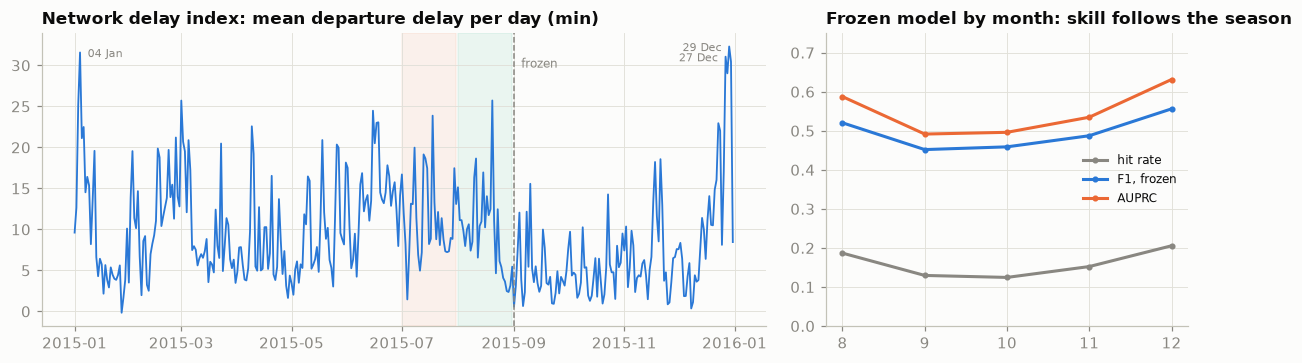

In [19]:
def psi(ref, cur, eps=1e-6):
    r, c = ref / ref.sum() + eps, cur / cur.sum() + eps
    return float(np.sum((c - r) * np.log(c / r)))

ref_carrier = fl.airline[train_rows].value_counts(); ref_origin = fl.origin[train_rows].value_counts()
ref_score = clf.predict_proba(X_tr[FEATS])[:, 1]
edges = np.quantile(ref_score, np.linspace(0, 1, 11)); edges[0], edges[-1] = -np.inf, np.inf
mon_rows = []
for m in [TEST_MONTH] + STREAM_MONTHS:
    if m == TEST_MONTH:
        ym, pm, mm = y_te, p_te, minutes_te
    else:
        ym, pm, mm = y[stream[m]], clf.predict_proba(X_stream[m][FEATS])[:, 1], reg.predict(X_stream[m][FEATS])
    yb = ym >= DELAY_MIN
    in_m = fl.month.values == m
    mon_rows.append({"month": m, "hit rate": yb.mean(), "F1 (frozen thr)": f1_score(yb, pm >= THR_F1),
                     "F1 (best possible)": f1_score(yb, pm >= f1_threshold(yb, pm)), "AUPRC": average_precision_score(yb, pm),
                     "AUPRC ÷ hit rate": average_precision_score(yb, pm) / yb.mean(), "MAE (min)": mean_absolute_error(ym, mm),
                     "flags (% of flights)": np.mean(pm >= THR_OP),
                     "PSI carrier": psi(ref_carrier, fl.airline[in_m].value_counts().reindex(ref_carrier.index, fill_value=0)),
                     "PSI origin": psi(ref_origin, fl.origin[in_m].value_counts().reindex(ref_origin.index, fill_value=0)),
                     "PSI score": psi(np.histogram(ref_score, edges)[0].astype(float), np.histogram(pm, edges)[0].astype(float))})
monitor = pd.DataFrame(mon_rows).set_index("month")
by_carrier = fl.groupby(["airline", "month"], observed=True).size().unstack(fill_value=0).loc[["AA", "US"], [5, 6, 7, 8]]
print("flights by month —", "; ".join(f"{airlines[c]} ({c}): " + ", ".join(f"{m}: {v:,.0f}" for m, v in r.items()) for c, r in by_carrier.iterrows()))
daily = fl.dep_delay.groupby(fl.doy).mean()                                     # NaN (never departed) skipped

fig, axes = plt.subplots(1, 2, figsize=(11, 3.4), gridspec_kw={"width_ratios": [2, 1]})
ax = axes[0]
dates = pd.Timestamp("2015-01-01") + pd.to_timedelta(daily.index - 1, unit="D")
ax.plot(dates, daily.values, lw=1.2, color=SERIES[0])
for mth, color in [(VALID_MONTH, SERIES[1]), (TEST_MONTH, SERIES[2])]:
    ax.axvspan(pd.Timestamp(f"2015-{mth:02d}-01"), pd.Timestamp(f"2015-{mth:02d}-01") + pd.offsets.MonthEnd(1), color=color, alpha=0.08)
ax.axvline(pd.Timestamp("2015-09-01"), color=MUTED, ls="--", lw=1); ax.text(pd.Timestamp("2015-09-05"), daily.max() * 0.92, "frozen", color=MUTED, fontsize=8)
top_days = daily.nlargest(3)
for d_, v in top_days.items():
    when = pd.Timestamp("2015-01-01") + pd.Timedelta(days=int(d_) - 1)
    ax.annotate(when.strftime("%d %b"), (when, v), xytext=(5 if when.month < 7 else -5, -3), textcoords="offset points",
                fontsize=7, color=MUTED, ha="left" if when.month < 7 else "right")
ax.set_title("Network delay index: mean departure delay per day (min)")
print("worst days:", ", ".join(f"{(pd.Timestamp('2015-01-01') + pd.Timedelta(days=int(d_) - 1)):%d %b} ({v:.0f} min)" for d_, v in top_days.items()),
      f"· median day {daily.median():.0f} min")
ax = axes[1]
ax.plot(monitor.index, monitor["hit rate"], "-o", ms=3, lw=2, color=MUTED, label="hit rate")
ax.plot(monitor.index, monitor["F1 (frozen thr)"], "-o", ms=3, lw=2, color=SERIES[0], label="F1, frozen")
ax.plot(monitor.index, monitor["AUPRC"], "-o", ms=3, lw=2, color=SERIES[1], label="AUPRC")
ax.set_ylim(0, 0.75); ax.set_xticks(monitor.index); ax.legend(fontsize=8)
ax.set_title("Frozen model by month: skill follows the season")
plt.tight_layout()
monitor.style.format({"hit rate": "{:.1%}", "F1 (frozen thr)": "{:.3f}", "F1 (best possible)": "{:.3f}", "AUPRC": "{:.3f}",
                      "AUPRC ÷ hit rate": "{:.2f}", "MAE (min)": "{:.1f}", "flags (% of flights)": "{:.1%}",
                      "PSI carrier": "{:.3f}", "PSI origin": "{:.3f}", "PSI score": "{:.3f}"})

Three readings for the monitoring plan (task C5):

1. **F1 follows the hit rate, not the model.** The frozen F1 falls from 0.52 in August to 0.45 in September and recovers to 0.56 in December, with hit rates of 18.7 %, 13.0 % and 20.6 %. Each month's best possible F1 is within 0.001 of the frozen one: the threshold has not gone stale. One fixed F1 floor would fail a healthy model in September and pass a weaker one in December.
2. **One input jumps, and it is not drift.** Carrier PSI is 0.80–0.81 in every month after the cut: US Airways, merged into American, stops reporting in July and American's flights nearly double (44,360 in June, 81,434 in July). An alert would fire for months on a relabelling; the runbook must say so. Airport-mix PSI stays at or below 0.022; score PSI reaches 0.20 in September, the calm season seen through the model. The **network delay index** is the signal that moves: its worst days, 27 and 29 December and 4 January, run at four times the median day.
3. **Labels are fast.** Realised F1 is known within hours and can trigger retraining a day later. The open question is *seasons*: this model has never seen autumn or the holiday peak (task S3).

## 8 · The module spine for this project

*Part C · Productionise · the targets your system must meet, with this notebook's numbers.*

The ten principles every project covers, updated with what this notebook found.

| Spine | In this project |
|---|---|
| Package and container (S02–S03) | `src/delay_prop/` (`features.py` with the as-of rule, `graph.py`, `train.py`, `serve.py`); `POST /predict` per flight two hours out; compose with Postgres for rotation and event tables (Neo4j optional) |
| Monitoring (S04) | F1 and MAE on realised arrivals (labels within hours); network delay index; PSI on airport mix (≤ 0.022), carrier mix (0.80–0.81: a relabelling) and score (0.20 in September); flags per hour against capacity; lookup latency |
| CI/CD gate (S05) | F1 at the frozen threshold and MAE on a fingerprinted August holdout (0.52, 16.0 min), compared season to season; a leakage test; the airport-code join check |
| MLflow tracking and registry (S06) | Horizon, look-back, minimum turn, feature families, training months, both thresholds, data and holdout SHA-256 |
| Offline / online training and serving | Online scoring from a near-real-time feature store fed by movement messages; offline monthly retraining on a rolling window |
| Data and model drift | Seasons (hit rate 12.4 % in October, 23.5 % in June), storm days, October's airport-code change, US Airways folded into American |
| Knowledge base and context (S07–S09) | Airport–route–carrier graph (322 airports, 4,533 routes, 1,251 carrier–airport links) plus rotations. Ablation: upstream context lifts F1 from 0.39 to 0.52, AUPRC from 0.36 to 0.59 |
| GenAI and context engineering (S10–S11) | OCC network-state brief citing scored flights; golden set of hub-hours; citation and outcome checks |
| Governance | CC0 DOT data; no personal data; tail numbers are public registrations; savings are assumptions |

## 9 · Student tasks

*Part C · Productionise · your assignment.*

This is an individual assignment: you pick one task from the catalogue, claimed first come, first served, so no other student works on it. **The model is given:** you package, evaluate, deploy and monitor this notebook's model; you do not design, tune or replace it. Where a task re-runs training (removing a leaking input, a retraining policy, a knowledge-base ablation), run the notebook's own training code with only its inputs or configuration changed. Work in your own repository, not in this notebook. Promote code into the `src/` package layout from Session 02, keep the notebook as a thin client, and record each design decision as an ADR in `docs/decisions/`. **Required:** all *Core* tasks (C1–C5), all *Extension* tasks (E1–E4) and Stretch **S2**, the GenAI task (Sessions 10–11). No API key is provided: run it on a local open-weight model, with a free hosted tier as an optional comparison, under the data rule for this task in [`docs/llm-access.md`](docs/llm-access.md). The other Stretch tasks are optional and count only towards the top band. The mark rewards the quality of each task, not the number done; the criteria are in `docs/task-rubric.md`.

### Core

- **C1 — Find and fix every trap.** `tests/test_features.py` must fail if any feature uses a value written after τ. Put the join check and October repair in the pipeline with a test, decide how cancellations enter the label, say what data would replace the actual-tail rotations, and report the honest August numbers.
- **C2 — Reproduce and freeze the given model.** Package the notebook's own data loading, features, training and scoring unchanged, retrain from a fresh clone with `SEED`, and show that your pipeline reproduces the numbers listed under *How this notebook is organised* within a tolerance you state. Add a data contract on the raw inputs (schema and value ranges, for example with pandera) and record any difference from the notebook in an ADR. No new features, learners or tuning.
- **C3 — Own the operating point.** Vary `ACTION_COST_USD`, `AVOIDED_COST_USD` and `OCC_CAPACITY_PER_HOUR`; show how threshold, flags per hour and value move; redo it for one carrier; write the ADR with the assumption you recommend and who signed it off.
- **C4 — Package, container and gate.** Feature construction in `src/` with tests, a versioned container for `serve.py`, and a CI gate on F1 and MAE against the frozen August holdout that refuses to run if its fingerprint changes and says what a new month is compared with (Sessions 02, 03, 05).
- **C5 — Register, document, monitor.** MLflow runs, a `champion` alias, a model card (October repair, as-of rule, cost assumptions, what the model cannot see) and a monitoring plan with the network delay index, the seasonal F1 comparison, the carrier relabelling and a retraining trigger (Sessions 04, 06).

### Extension

- **E1 — The knowledge-base ablation (Sessions 07–09).** Model airports, routes, carriers, aircraft and legs as a knowledge graph, validate it with SHACL (each leg starts where the previous one ended), and re-run the ablation with and without upstream-network context at every horizon.
- **E2 — Errors by airport and carrier.** Which hubs and carriers does the model miss most? Do regional carriers (OO, EV, MQ) fare worse? How should `US`→`AA` be handled?
- **E3 — Governance.** Where would an OCC decision-support model sit under the EU AI Act for a European carrier? Read Annex III and the civil-aviation acts listed in Annex I and record your reading. What does human oversight mean at 150 flags an hour?
- **E4 — Is the score a probability at every horizon?** Check the given model's calibration at each horizon on July (no refitting) and state in the model card where the operating point may and may not treat it as one.

### Stretch

- **S1 — Streaming features.** Replay August's movement messages through an event loop that maintains airport and rotation state online; measure latency per prediction and cost per million (Session 11).
- **S2 — The OCC brief with an LLM (Sessions 10–11).** Build a golden set of 30 hub-hours; give an LLM only the scored candidate table and ask for a structured brief with flight citations; score citation validity, coverage and factuality against outcomes; test prompt injection.
- **S3 — Retraining policy.** Simulate monthly retraining with a one-day label delay and a rolling window. Does it beat the frozen model each month, and at what cost?

## 10 · Hand-in checklist

*Part C · Productionise · tick every box before you submit.*

- [ ] Repository in the Session 02 layout; fresh-clone test passes; `data/` not committed
- [ ] `README.md` states the months, the sample sizes and how to obtain the data (Kaggle, CC0)
- [ ] Join check and October repair in the pipeline; as-of test; label rule for cancellations
- [ ] Month-split evaluation only; ablation and horizon curve reproduced; operating point with its ADR
- [ ] CI with tests and the F1/MAE gate on the frozen holdout; registered model with model card; seasonal monitoring plan
- [ ] One-page recommendation to the head of the OCC: how early, how accurate, at what workload
- [ ] Required tasks done: C1–C5, E1–E4 and S2
- [ ] GenAI task runs on a local model; any hosted run follows the data rule and logs provider, model and cost
- [ ] Reflective diary entry: what you chose, what you rejected, what evidence would change your mind

---

### Appendix — environment and references

- Python ≥ 3.11; `pandas`, `pyarrow`, `numpy`, `scipy`, `networkx`, `scikit-learn`, `lightgbm`, `matplotlib`, `kagglehub` (pinned in `requirements.txt`).
- US Department of Transportation, Bureau of Transportation Statistics. *Airline On-Time Performance Data* and the *Air Travel Consumer Report* (the source of this dataset and of the cause-of-delay definitions).
- AhmadBeygi, S., Cohn, A., Guan, Y., Belobaba, P. (2008). *Analysis of the potential for delay propagation in passenger airline networks.* Journal of Air Transport Management 14(5).
- Pyrgiotis, N., Malone, K. M., Odoni, A. (2013). *Modelling delay propagation within an airport network.* Transportation Research Part C 27.
- Huyen, C. (2022). *Designing Machine Learning Systems*, Ch. 5 (feature engineering, leakage) and Ch. 8 (distribution shifts and monitoring).

In [20]:
print(f"pandas {pd.__version__} · pyarrow {pa.__version__} · lightgbm {lgb.__version__} · networkx {nx.__version__} · "
      f"scikit-learn {sklearn.__version__} · numpy {np.__version__}")
print(f"notebook finished · total wall time {time.time()-T_START:.0f}s")

pandas 3.1.0 · pyarrow 26.0.0 · lightgbm 4.7.0 · networkx 3.7 · scikit-learn 1.9.1 · numpy 2.5.4
notebook finished · total wall time 211s
